# 09 · Isle Royale: predator–prey equations (Q6)

**Question:** do predator–prey equations fit the 1959–2015 counts, and do wolves kill according to moose numbers
(prey-dependent) or moose per wolf (ratio-dependent)?

r = moose growth rate, K = moose ceiling, a = attack rate, h = handling time (years per moose killed),
e = new wolves per moose killed, d = wolf death rate. Kill rate f is in **moose killed per wolf per year**.

| Model | Moose | Wolves |
|---|---|---|
| Lotka–Volterra | dM/dt = rM − aMW | dW/dt = e·aMW − dW |
| Rosenzweig–MacArthur | dM/dt = rM(1−M/K) − f(M)·W, f = aM/(1+ahM) | dW/dt = e·f·W − dW |
| Ratio-dependent kill rate | f = α(M/W) / (1 + αh(M/W)) | |

Sections
1. Kill rates vs M and vs M/W (needs the yearly kill-rate series from the annual reports)
2. Discrete-time model on growth rates (prey- vs ratio-dependent), plus the wolf equation
3. Whole-system ODE fits (Lotka–Volterra, Rosenzweig–MacArthur)
4. Do the fitted models cycle, and how long is the cycle compared with Q5?

In [1]:
import sys, warnings
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "scripts"))
import tsa_spec as spec

FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
TAB = ROOT / "reports" / "tables"; TAB.mkdir(parents=True, exist_ok=True)

# One colour per species in every figure (moose = blue, wolves = orange)
C_MOOSE, C_WOLF, C_3, C_4 = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
SHADE = {"parvo_crash": "#d9d6cf", "near_extinction": "#e8e5df", "reintroduction": "#f0efec"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e6e6", "grid.linewidth": 0.6, "lines.linewidth": 2,
                     "axes.titleweight": "bold", "figure.dpi": 110})

ir = pd.read_csv(ROOT / "data" / "processed" / "isle_royale_annual.csv", index_col="Year")
M_all, W_all = ir["Moose"].astype(float), ir["Wolves"].astype(float)
MAIN = list(range(1959, 2016))                      # main sample (brief): 1959-2015
M, W = M_all.loc[1959:2015], W_all.loc[1959:2015]
print("tsa_spec", spec.SPEC_VERSION, "| main sample", MAIN[0], "-", MAIN[-1], f"({len(MAIN)} years)")

import json
from scipy.integrate import solve_ivp
from scipy.optimize import curve_fit, least_squares
from scipy.signal import find_peaks
import statsmodels.api as sm

def aic_ls(resid, k):
    """Gaussian AIC for a least-squares fit: n log(RSS/n) + 2k."""
    n = len(resid); return n * np.log(np.sum(np.square(resid)) / n) + 2 * k

# Reference value for checking implied kill rates: the project's 1971-2011 winter average,
# 0.7 moose per wolf per month (2018-19 annual report), i.e. about 8.4 per wolf per year.
KILL_REF = 0.7 * 12

tsa_spec 1.3 (2026-11-18) | main sample 1959 - 2015 (57 years)


## 1. Kill rates vs moose (prey-dependent) and vs moose per wolf (ratio-dependent)
This is the direct test (the comparison Vucetich, Peterson & Schaefer 2002 made on Isle Royale). It needs the yearly
per-capita kill rate, which the annual reports publish only as a figure. Fill
`data/raw/isle_royale_kill_rates_TO_FILL.csv` (column `Kill_rate_per_wolf_per_month`) from the reports and rebuild the
data file; this section then runs by itself. Until then, section 2 answers the same question indirectly from the counts.

In [2]:
kr = ir.loc[:2015, "Kill_rate_per_wolf_per_month"].dropna()
print(f"Yearly kill rates available (1959–2015): {len(kr)}")
if len(kr) >= 10:
    kd = pd.DataFrame({"k": kr * 12, "M": M.reindex(kr.index), "R": (M / W).reindex(kr.index)}).dropna()
    h2 = lambda x, a, h: a * x / (1 + a * h * x)
    fits_k = {}
    for nm, col, p0 in [("prey-dependent (vs M)", "M", [0.02, 0.1]), ("ratio-dependent (vs M/W)", "R", [0.5, 0.1])]:
        p, cv = curve_fit(h2, kd[col], kd["k"], p0=p0, bounds=([1e-6, 1e-3], [50, 5]), maxfev=20000)
        res = kd["k"] - h2(kd[col], *p)
        fits_k[nm] = {"a or alpha": p[0], "h": p[1], "AIC": aic_ls(res, 2), "R2": 1 - res.var() / kd["k"].var()}
    display(pd.DataFrame(fits_k).T.round(4))
else:
    print("Not enough kill-rate data yet; see section 2 for the indirect comparison.")

Yearly kill rates available (1959–2015): 0
Not enough kill-rate data yet; see section 2 for the indirect comparison.


## 2. Discrete-time model on moose growth rates
The brief's fallback, and the form used for the simulation in notebook 10:

r_M,t = r(1 − M_(t−1)/K) − f_(t−1)·W_(t−1)/M_(t−1) + ε_t

f·W/M is the share of moose killed in the year. Three versions are fitted with `curve_fit` and compared by AIC:
logistic only (no wolves), prey-dependent f, ratio-dependent f.

**Handling time is bounded to h ≥ 0.05 years** (at most 20 moose per wolf per year, about twice the highest kill
rate recorded on Isle Royale). Without the bound the ratio-dependent fit drifts to h → 0, where f·W/M becomes a
constant and the wolves drop out of the model, which is not a predator–prey model at all.

In [3]:
d = pd.DataFrame({"r": np.log(M).diff(), "M": M.shift(1), "W": W.shift(1)}).dropna()
X = (d["M"].values, d["W"].values)

def kill_prey(m, w, a, h):  return a * m / (1 + a * h * m)
def kill_ratio(m, w, al, h): R = m / w; return al * R / (1 + al * h * R)
def g_logistic(X, r, K):      m, w = X; return r * (1 - m / K)
def g_prey(X, r, K, a, h):    m, w = X; return r * (1 - m / K) - kill_prey(m, w, a, h) * w / m
def g_ratio(X, r, K, al, h):  m, w = X; return r * (1 - m / K) - kill_ratio(m, w, al, h) * w / m

specs = {
    "logistic (no wolves)": (g_logistic, [0.3, 2000], [0, 300], [3, 2e4], ["r", "K"]),
    "prey-dependent":       (g_prey, [0.3, 2500, 0.01, 0.1], [0, 300, 1e-6, 0.05], [3, 2e4, 1, 1], ["r", "K", "a", "h"]),
    "ratio-dependent":      (g_ratio, [0.3, 2500, 0.3, 0.1], [0, 300, 1e-4, 0.05], [3, 2e4, 50, 1], ["r", "K", "alpha", "h"]),
}
disc, rows = {}, []
for nm, (fn, p0, lb, ub, names) in specs.items():
    best = None
    for s in (1, 0.3, 3, 10):                       # several starting points; keep the best
        for h0 in (0.06, 0.1, 0.3):
            start = list(p0)
            if len(start) == 4: start[2] *= s; start[3] = h0
            try:
                p, cv = curve_fit(fn, X, d["r"].values, p0=start, bounds=(lb, ub), maxfev=20000)
            except RuntimeError:
                continue
            res = d["r"].values - fn(X, *p)
            a_ = aic_ls(res, len(p))
            if best is None or a_ < best["AIC"]:
                best = {"p": p, "se": np.sqrt(np.diag(cv)), "res": res, "AIC": a_}
    disc[nm] = best
    row = {"model": nm, "AIC": best["AIC"], "resid SD": best["res"].std(ddof=len(best["p"]))}
    for k, v, se in zip(names, best["p"], best["se"]):
        row[k] = v; row[f"se({k})"] = se
    if len(names) == 4:
        kf = kill_prey if nm == "prey-dependent" else kill_ratio
        fk = kf(X[0], X[1], *best["p"][2:])
        row["at bound h=0.05"] = bool(np.isclose(best["p"][3], 0.05, atol=1e-4))
        row["implied kill/wolf/yr: median"] = np.median(fk)
        row["min"], row["max"] = fk.min(), fk.max()
    rows.append(row)
disc_tab = pd.DataFrame(rows).set_index("model")
disc_tab["ΔAIC"] = disc_tab["AIC"] - disc_tab["AIC"].min()
disc_tab.round(4).to_csv(TAB / "IR_Q6_discrete_model_comparison.csv")
print(f"n = {len(d)} years ({d.index.min()}–{d.index.max()}); reference kill rate ≈ {KILL_REF:.1f} moose/wolf/yr")
disc_tab.round(3).T

n = 56 years (1960–2015); reference kill rate ≈ 8.4 moose/wolf/yr


model,logistic (no wolves),prey-dependent,ratio-dependent
AIC,-187.862,-195.189,-196.579
resid SD,0.184,0.169,0.167
r,0.156,0.511,0.681
se(r),0.063,0.128,0.261
K,1078.857,1717.232,1900.542
se(K),175.432,227.097,459.128
a,NaN,0.03,NaN
se(a),NaN,0.039,NaN
h,NaN,0.089,0.05
se(h),NaN,0.063,0.063


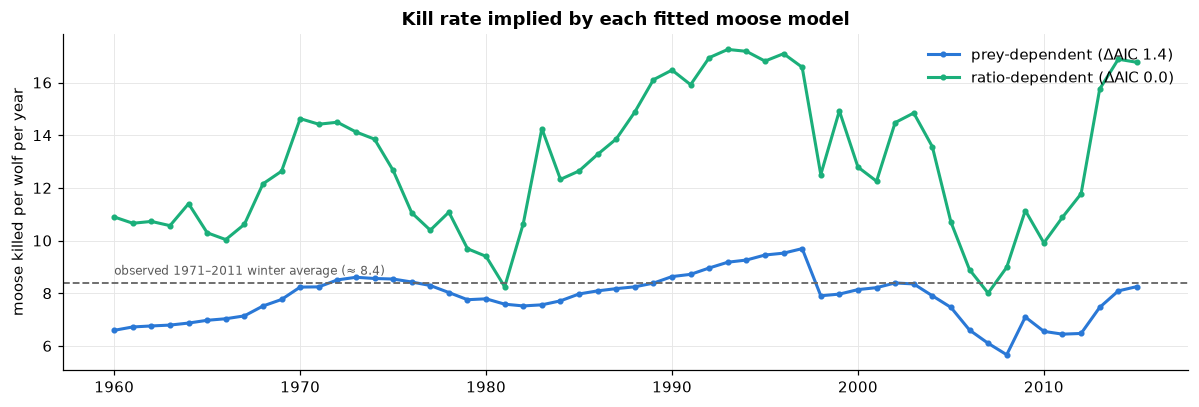

In [4]:
fig, ax = plt.subplots(figsize=(11, 3.8))
for nm, col, kf in [("prey-dependent", C_MOOSE, kill_prey), ("ratio-dependent", C_3, kill_ratio)]:
    fk = kf(X[0], X[1], *disc[nm]["p"][2:])
    ax.plot(d.index, fk, color=col, marker="o", ms=3, label=f"{nm} (ΔAIC {disc_tab.loc[nm, 'ΔAIC']:.1f})")
ax.axhline(KILL_REF, color="0.4", ls="--", lw=1.2)
ax.text(d.index.min(), KILL_REF + 0.3, "observed 1971–2011 winter average (≈ 8.4)", fontsize=8, color="0.35")
ax.set_ylabel("moose killed per wolf per year"); ax.legend(frameon=False, loc="upper right")
ax.set_title("Kill rate implied by each fitted moose model")
fig.tight_layout(); fig.savefig(FIG / "IR_09_implied_kill_rates.png", dpi=200)

### 2.1 Wolf equation
r_W,t = e·f_(t−1) − d + η_t: wolves grow when each wolf gets more food. Fitted by OLS with f from each moose model.

In [5]:
rW = np.log(W).diff()
wolf_eq = {}
for nm, kf in [("prey-dependent", kill_prey), ("ratio-dependent", kill_ratio)]:
    f_lag = pd.Series(kf(M.values, W.values, *disc[nm]["p"][2:]), index=M.index).shift(1)
    dd = pd.concat([rW.rename("rW"), f_lag.rename("f")], axis=1).dropna()
    o = sm.OLS(dd["rW"], sm.add_constant(dd["f"])).fit()
    wolf_eq[nm] = {"e": o.params["f"], "se(e)": o.bse["f"], "p(e)": o.pvalues["f"], "d": -o.params["const"],
                   "se(d)": o.bse["const"], "R2": o.rsquared, "resid SD": np.sqrt(o.scale), "n": int(o.nobs),
                   "resid": o.resid}
weq = pd.DataFrame({k: {kk: vv for kk, vv in v.items() if kk != "resid"} for k, v in wolf_eq.items()}).T
weq.round(4).to_csv(TAB / "IR_Q6_wolf_equation.csv"); weq.round(3)

,e,se(e),p(e),d,se(d),R2,resid SD,n
prey-dependent,0.062,0.044,0.168,0.518,0.349,0.035,0.293,56.0
ratio-dependent,0.021,0.015,0.167,0.304,0.197,0.035,0.293,56.0


## 3. Whole-system ODE fits
Both equations are solved together with `solve_ivp` from fitted 1959 starting values, and the parameters are chosen by
`least_squares` to minimise the gap between log observed and log simulated counts (both species, equal weight).
Parameters are fitted on the log scale (keeps them positive); each model is started from several points.
Because the fitted Rosenzweig–MacArthur model puts the wolf death rate far above anything biologically plausible,
it is refitted with d fixed at the Lotka–Volterra estimate, as the brief suggests.

In [6]:
YRS = np.arange(1959, 2016); T = (YRS - 1959).astype(float)
obs = np.r_[np.log(M.values), np.log(W.values)]

def lv(t, y, r, a, e, d):        m, w = y; return [r*m - a*m*w, e*a*m*w - d*w]
def rm(t, y, r, K, a, h, e, d):  m, w = y; f = a*m/(1 + a*h*m); return [r*m*(1 - m/K) - f*w, e*f*w - d*w]

def _blowup(t, y, *p):              # stop a run whose populations explode or collapse (bad parameter guesses)
    return min(1e6 - max(y), min(y) - 1e-6)
_blowup.terminal = True

def simulate(fn, p, y0, t=T):
    s = solve_ivp(fn, (0, t[-1]), y0, t_eval=t, args=tuple(p), rtol=1e-4, atol=1e-4, method="LSODA", events=_blowup)
    return s.y if s.success and s.y.shape[1] == len(t) else np.full((2, len(t)), np.nan)

def fit_ode(fn, p0, names, fixed=None, starts=4, seed=0):
    fixed = fixed or {}
    free = [n for n in names if n not in fixed]
    def full(lp):
        q = dict(zip(free, np.exp(lp[:len(free)]))); q.update(fixed)
        return [q[n] for n in names], np.exp(lp[len(free):])
    def resid(lp):
        p, y0 = full(lp); y = simulate(fn, p, y0)
        if not np.all(np.isfinite(y)) or np.any(y <= 0): return np.full(len(obs), 5.0)
        return np.r_[np.log(y[0]), np.log(y[1])] - obs
    rng, best = np.random.default_rng(seed), None
    base = np.log([p0[n] for n in free] + [M.iloc[0], W.iloc[0]])
    for i in range(starts):
        x0 = base + (rng.normal(0, 0.4, len(base)) if i else 0)
        r = least_squares(resid, x0, max_nfev=400)
        if best is None or r.cost < best.cost: best = r
    p, y0 = full(best.x)
    res = resid(best.x)
    return {"params": dict(zip(names, p)), "y0": y0, "resid": res, "AIC": aic_ls(res, len(best.x)),
            "RMSE log moose": np.sqrt(np.mean(res[:len(T)]**2)), "RMSE log wolves": np.sqrt(np.mean(res[len(T):]**2))}

ode = {}
ode["Lotka–Volterra"] = fit_ode(lv, {"r": 0.3, "a": 0.015, "e": 0.08, "d": 0.3}, ["r", "a", "e", "d"])
ode["Rosenzweig–MacArthur"] = fit_ode(rm, {"r": 0.4, "K": 3000, "a": 0.015, "h": 0.05, "e": 0.04, "d": 0.26},
                                       ["r", "K", "a", "h", "e", "d"])
d_fix = ode["Lotka–Volterra"]["params"]["d"]
ode["Rosenzweig–MacArthur, d fixed"] = fit_ode(rm, {"r": 0.4, "K": 3000, "a": 0.015, "h": 0.05, "e": 0.04},
                                                ["r", "K", "a", "h", "e", "d"], fixed={"d": d_fix})
print(f"d fixed at the Lotka–Volterra estimate: {d_fix:.3f} per year")

d fixed at the Lotka–Volterra estimate: 0.262 per year


In [7]:
def cycle_period(fn, p, y0, years=600, dt=0.25):
    """Run the fitted model long enough for transients to die out, then measure peak-to-peak time of moose."""
    t = np.arange(0, years, dt); y = simulate(fn, p, y0, t)
    tail = y[0][len(t) // 2:]
    pk, _ = find_peaks(tail)
    if len(pk) < 3 or np.ptp(tail) < 1:
        return np.nan, "settles to equilibrium", np.ptp(tail)
    amp_first, amp_last = np.ptp(tail[: len(tail) // 4]), np.ptp(tail[-len(tail) // 4:])
    kind = "neutral cycles (amplitude set by start)" if fn is lv else (
        "stable limit cycle" if abs(amp_last - amp_first) < 0.02 * amp_first else "damped/growing oscillation")
    return np.mean(np.diff(pk)) * dt, kind, np.ptp(tail)

fns = {"Lotka–Volterra": lv, "Rosenzweig–MacArthur": rm, "Rosenzweig–MacArthur, d fixed": rm}
rows = []
for nm, f_ in ode.items():
    per, kind, amp = cycle_period(fns[nm], list(f_["params"].values()), f_["y0"])
    f_["period"] = per
    row = {"model": nm, "AIC": f_["AIC"], "RMSE log moose": f_["RMSE log moose"], "RMSE log wolves": f_["RMSE log wolves"],
           "long-run behaviour": kind, "cycle period (yr)": per} | {k: v for k, v in f_["params"].items()}
    if "h" in f_["params"]:
        pr = f_["params"]; row["max kill/wolf/yr (1/h)"] = 1 / pr["h"]
        row["kill/wolf/yr at M=1000"] = pr["a"] * 1000 / (1 + pr["a"] * pr["h"] * 1000)
    else:
        row["kill/wolf/yr at M=1000"] = f_["params"]["a"] * 1000
    rows.append(row)
ode_tab = pd.DataFrame(rows).set_index("model")
ode_tab.round(4).to_csv(TAB / "IR_Q6_ode_fits.csv")
ode_tab.round(3).T

model,Lotka–Volterra,Rosenzweig–MacArthur,"Rosenzweig–MacArthur, d fixed"
AIC,-246.95,-270.43,-257.872
RMSE log moose,0.264,0.262,0.264
RMSE log wolves,0.369,0.305,0.338
long-run behaviour,neutral cycles (amplitude set by start),stable limit cycle,settles to equilibrium
cycle period (yr),23.375,29.556,NaN
r,0.283,0.603,0.322
a,0.013,0.154,0.017
e,0.021,0.154,0.018
d,0.262,2.174,0.262
kill/wolf/yr at M=1000,13.024,14.187,14.923


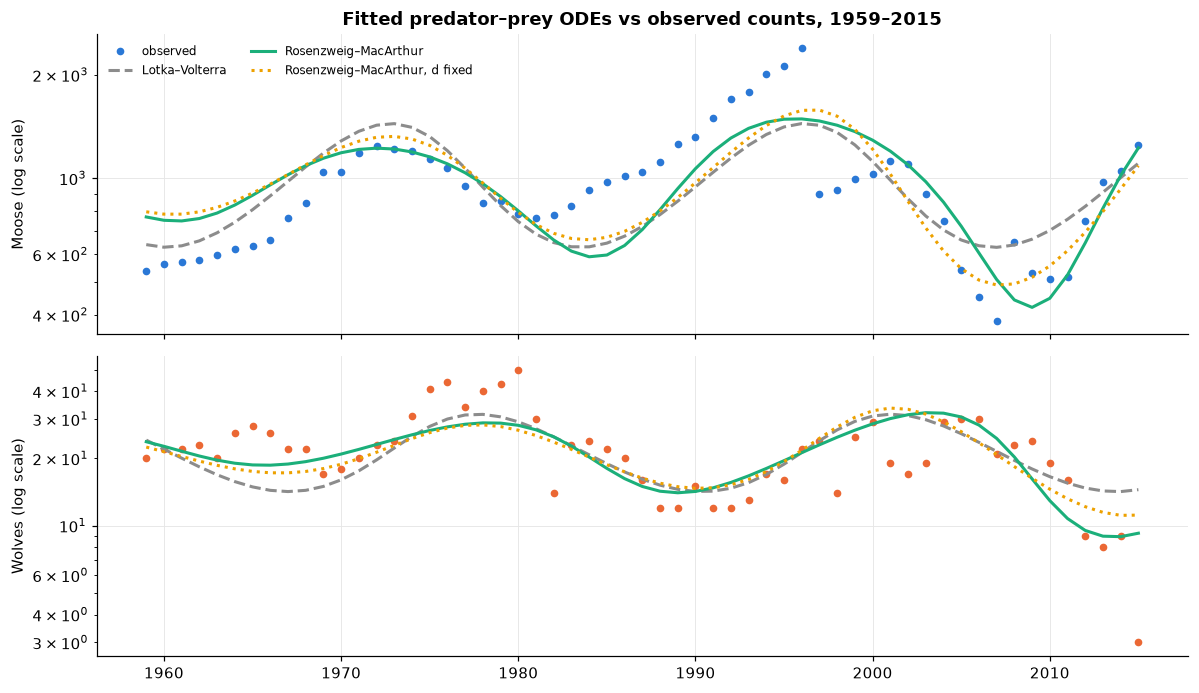

In [8]:
fig, axes = plt.subplots(2, 1, figsize=(11, 6.4), sharex=True)
styles = {"Lotka–Volterra": ("0.55", "--"), "Rosenzweig–MacArthur": (C_3, "-"), "Rosenzweig–MacArthur, d fixed": (C_4, ":")}
for ax, s, col, lab, i in [(axes[0], M, C_MOOSE, "Moose", 0), (axes[1], W, C_WOLF, "Wolves", 1)]:
    ax.plot(s.index, s, "o", color=col, ms=4, label="observed")
    for nm, f_ in ode.items():
        y = simulate(fns[nm], list(f_["params"].values()), f_["y0"])
        c, ls = styles[nm]; ax.plot(YRS, y[i], ls, color=c, lw=2, label=nm)
    ax.set_yscale("log"); ax.set_ylabel(f"{lab} (log scale)")
axes[0].legend(frameon=False, ncol=2, fontsize=8, loc="upper left")
axes[0].set_title("Fitted predator–prey ODEs vs observed counts, 1959–2015")
fig.tight_layout(); fig.savefig(FIG / "IR_10_ode_fit.png", dpi=200)

## 4. Save parameters for the stochastic simulation (notebook 10)

In [9]:
q6 = {"note": "Discrete-time moose model and wolf equation fitted in notebook 09 on 1960-2015 growth rates.",
      "kill_rate_units": "moose per wolf per year"}
for nm in ["prey-dependent", "ratio-dependent"]:
    p = disc[nm]["p"]
    q6[nm] = {"r": p[0], "K": p[1], ("a" if nm == "prey-dependent" else "alpha"): p[2], "h": p[3],
              "sigma_M": float(disc[nm]["res"].std(ddof=4)),
              "e": wolf_eq[nm]["e"], "d": wolf_eq[nm]["d"], "sigma_W_total": float(wolf_eq[nm]["resid SD"]),
              "wolf_resid": wolf_eq[nm]["resid"].round(5).to_dict()}
json.dump(q6, open(TAB / "IR_Q6_params.json", "w"), indent=1, default=float)
print("Saved", (TAB / "IR_Q6_params.json").relative_to(ROOT))

Saved reports/tables/IR_Q6_params.json


## Summary (plain English)

1. **Kill-rate data.** The yearly kill rates are not yet entered, so the direct test in section 1 is pending. Sections 2–3 answer the question indirectly from the counts.

2. **Wolves are needed to explain moose growth.** Adding predation to logistic growth improves the fit clearly (ΔAIC 7.3 for prey-dependent, 8.7 for ratio-dependent).

3. **Prey- vs ratio-dependent: the counts can't decide.** The two differ by ΔAIC = 1.4, below the usual threshold of 2. The prey-dependent version is the more realistic one: it implies a median kill of 8.0 moose per wolf per year (range 5.7–9.7), close to the observed winter average of about 8.4. The ratio-dependent version implies 12.6 (up to 17.3) and sits on the handling-time limit. Individual parameters are loosely pinned down (for example, the standard error of the attack rate is larger than the estimate), so the kill-rate series is needed to settle this.

4. **The wolf equation is weak year to year, but its balance point is right.** Wolf growth barely follows last year's kill rate (e = 0.062, p = 0.17, R² = 0.03). But wolves in this model hold steady when each kills d/e ≈ 8.4 moose per year, almost exactly the observed average. The weak fit reflects timing, not absence: notebook 8 shows wolves respond to moose with a delay of 1–3 years (p = 0.026) and track moose about 8 years later, while this equation only allows a one-year response. Disease (the 1980–82 parvovirus) and inbreeding also drive wolf numbers and are not in the model.

5. **The ODEs follow the timing but miss the extremes.** Rosenzweig–MacArthur fits better than Lotka–Volterra (AIC −270 vs −247). Both track the timing of the main rises and falls, but they miss the 1990s moose boom (fitted peak about 1,500 vs observed 2,400), the 1980 wolf peak and parvovirus crash, and the 2015 collapse to 3 wolves. Smooth deterministic equations can't produce shocks like these; notebook 10 adds randomness for that reason.

6. **No plausible model produces a self-sustaining cycle.** Lotka–Volterra gives neutral cycles of about 23 years. The free Rosenzweig–MacArthur fit gives a stable 29.6-year cycle, but only with a wolf death rate of 2.17 per year and a conversion rate of 0.15, both implausible. With the death rate fixed at a plausible 0.26, the model drifts back toward Lotka–Volterra (K becomes unbounded, handling time goes to 0) and settles to a fixed point. So the model families can produce 23–30-year cycles, in line with the rough 25–30 years in notebook 8, but this is not independent evidence of a cycle.

7. **Which model goes forward.** All whole-system ODE fits imply kill rates of 13–15 per wolf per year at 1,000 moose, well above the observed 8.4. The discrete prey-dependent model gives realistic kill rates and a realistic wolf balance point, so it is the model used for the extinction simulation in notebook 10.